# TOFFEE Quickstart: Detecting Flares

This notebook is the whole core TOFFEE workflow end to end: get a light curve, detrend it, detect flares, and look at what came out. It moves fast and skips over some details on purpose: notebook 2 explains `flatten()` properly, and notebook 3 explains the flare-decay modeling underneath `detect_flares()`. If you just want to see TOFFEE work, this is the notebook.

In [1]:
import numpy as np
import pandas as pd
import toffee

## 1. Get a light curve

TOFFEE works on any TESS (or Kepler) light curve you hand it. It doesn't download data itself. The example target below is TIC 84336253, sector 43: a real light curve with a secondary flare landing in the decay of a large primary flare, a genuine overlapping ("sympathetic") flare pair, which notebook 3 comes back to in detail.

In [2]:
################ TUTORIAL TARGET ################
#change these two values to try a different star/sector
TIC_ID = 84336253
SECTOR = 43

In [3]:
import lightkurve as lk

search_result = lk.search_lightcurve(f'TIC {TIC_ID}', mission = 'TESS', author = 'SPOC',
                                     exptime = 120, sector = SECTOR)
lc = search_result.download()
lc

time,flux,flux_err,timecorr,cadenceno,centroid_col,centroid_row,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,electron / s,electron / s,d,,pix,pix,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,float32,int32,float64,float64,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
2474.1696426682415,1.8693135e+02,5.7815237e+00,2.1960407e-03,897633,1331.22087,1621.75010,1.0521178e+02,3.1812596e+00,5.6443884e+02,1.2039918e+00,1.8693135e+02,5.7815237e+00,0,———,———,———,———,1331.22087,1.3747131e-02,1621.75010,1.3578815e-02,5.2582845e-03,-6.4765804e-02
2474.1710316892313,2.0272585e+02,5.7964716e+00,2.1961734e-03,897634,1331.24106,1621.72786,1.1401851e+02,3.1894848e+00,5.6309503e+02,1.2033739e+00,2.0272585e+02,5.7964716e+00,0,———,———,———,———,1331.24106,1.2619127e-02,1621.72786,1.2528968e-02,1.6863519e-02,-4.2340115e-02
2474.1724207102206,1.8351060e+02,5.7540612e+00,2.1963061e-03,897635,1331.22960,1621.75050,1.0316769e+02,3.1661484e+00,5.6168262e+02,1.1999220e+00,1.8351060e+02,5.7540612e+00,0,———,———,———,———,1331.22960,1.3893123e-02,1621.75050,1.3794512e-02,6.3600237e-03,-5.5060763e-02
2474.17380973121,1.8967242e+02,5.7675476e+00,2.1964388e-03,897636,1331.22782,1621.74536,1.0672661e+02,3.1735692e+00,5.6126562e+02,1.2016524e+00,1.8967242e+02,5.7675476e+00,0,———,———,———,———,1331.22782,1.3467155e-02,1621.74536,1.3348713e-02,4.6838322e-03,-6.8171300e-02
2474.175198752433,1.8900803e+02,5.7579393e+00,2.1965718e-03,897637,1331.20189,1621.73303,1.0643208e+02,3.1682823e+00,5.6021973e+02,1.2002347e+00,1.8900803e+02,5.7579393e+00,0,———,———,———,———,1331.20189,1.3569307e-02,1621.73303,1.3345970e-02,6.7093479e-03,-6.2502310e-02
2474.1765877734224,1.8856271e+02,5.7549872e+00,2.1967045e-03,897638,1331.20636,1621.74683,1.0632416e+02,3.1666579e+00,5.5900488e+02,1.1985700e+00,1.8856271e+02,5.7549872e+00,0,———,———,———,———,1331.20636,1.3584283e-02,1621.74683,1.3370058e-02,8.4743584e-03,-5.1840510e-02
2474.1779767944126,1.8941260e+02,5.7562742e+00,2.1968372e-03,897639,1331.21441,1621.76751,1.0681253e+02,3.1673663e+00,5.5558545e+02,1.1944531e+00,1.8941260e+02,5.7562742e+00,0,———,———,———,———,1331.21441,1.3435151e-02,1621.76751,1.3400610e-02,1.2875082e-02,-5.6610193e-02
2474.179365815402,1.8739302e+02,5.7345052e+00,2.1969699e-03,897640,1331.21004,1621.73745,1.0571426e+02,3.1553879e+00,5.5506812e+02,1.1945629e+00,1.8739302e+02,5.7345052e+00,0,———,———,———,———,1331.21004,1.3565890e-02,1621.73745,1.3392296e-02,6.6135544e-03,-6.0618736e-02


In [4]:
#lightkurve wraps flux/flux_err in an astropy MaskedNDArray, which TOFFEE's functions
#don't expect -- convert everything to plain numpy arrays first
time = np.asarray(lc.time.value, dtype = float)
flux = np.asarray(lc.flux.value, dtype = float)
flux_err = np.asarray(lc.flux_err.value, dtype = float)
quality = np.asarray(lc.quality.value, dtype = int)

#flatten() doesn't drop non-finite cadences itself, so do it here -- PDCSAP flux has
#NaNs at flagged/missing cadences (about 7% of this particular light curve)
finite = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
print(f'dropping {(~finite).sum()} non-finite cadence(s) of {len(time)}')
time, flux, flux_err, quality = time[finite], flux[finite], flux_err[finite], quality[finite]

dropping 1209 non-finite cadence(s) of 16845


## 2. Detrend with `flatten()`

`flatten()` removes the TESS-orbit-scale trend (first a quadratic fit per orbit, then an optional `wotan` flatten over a short window) so flares stand out against a flat baseline. With `short_window` set and no `periodogram` argument, it returns four values. Notebook 2 covers exactly what each one means, and why the count changes with different arguments.

In [5]:
orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window = 0.25)

#lc_wotan bundles the flattened flux, its errors, and the fitted trend as
#lc_wotan[0], lc_wotan[1], lc_wotan[2]
flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]

#flatten() only keeps cadences that fall inside a known TESS orbit window, so check quality
#still lines up one-to-one before reusing it -- if you swap in a different target and it
#doesn't, fall back to no quality filtering rather than misaligning by position
if len(orbit_time) == len(quality):
    orbit_quality = quality
else:
    print(f'{len(quality) - len(orbit_time)} cadence(s) fell outside TESS orbit coverage and '
          'were dropped by flatten() -- skipping quality filtering to avoid misalignment.')
    orbit_quality = np.zeros(len(orbit_time))

## 3. Detect flares

`detect_flares()` takes the detrended time/flux/flux_err plus a `quality` array (pass an all-zero array to skip quality filtering) and returns a pandas DataFrame, one row per flare.

In [6]:
flares = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, orbit_quality)
flares

,T_peak,T_start,T_end,Amplitude,ED,Primary_or_Secondary,Num_Points,Num_Abv_Threshold,Amp_Sigma
0,2475.422539,2475.414205,2475.439207,0.296309,333.924647,primary,18,15,10.766277
1,2493.110102,2493.105935,2493.193441,3.026989,5359.732806,primary,64,57,109.984543
2,2493.115658,2493.115658,2493.119825,0.424544,86.751489,secondary,4,4,14.835562


Column meanings:

| Column | Meaning |
|---|---|
| `T_peak`, `T_start`, `T_end` | Flare peak/start/end time, in the same units as the input `time` (TESS BJD - 2,457,000) |
| `Amplitude` | Peak height above baseline, in relative flux (baseline is 1.0) |
| `ED` | Equivalent duration, in **seconds** (not days): the time the star would need to shine at its normal, quiescent brightness to radiate as much extra light as the whole flare did. A bigger or longer flare has a bigger ED. Notebook 6 uses it to get an actual flare energy. |
| `Primary_or_Secondary` | `'primary'`, `'secondary'`, or `'tertiary'`: see notebook 3 for what secondary/tertiary means |
| `Num_Points` | Number of cadences in the flare |
| `Num_Abv_Threshold` | Number of those cadences above the detection threshold |
| `Amp_Sigma` | Amplitude divided by the light curve's global sigma: how many multiples of the light curve's typical noise level the peak stands above the baseline. Sigma here means the scatter in the quiescent, non-flaring flux, so a bigger `Amp_Sigma` is a flare that stands out more clearly from the noise, not necessarily a bigger flare in absolute terms. |

## 4. The thresholds that matter

`detect_flares()` takes about twenty arguments, but its own docstring says only a few are worth tuning routinely: `primary_threshold`, `secondary_threshold`, `num_consec`, and `num_consec_sec`. Here's what changing the two thresholds does to this light curve:

In [7]:
#rerun detection at a few thresholds and compare how many flares come out
for threshold in (2.0, 2.5, 3.0):
    trial = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, orbit_quality,
                                 primary_threshold = threshold, secondary_threshold = threshold)
    num_primary = (trial['Primary_or_Secondary'] == 'primary').sum()
    num_other = len(trial) - num_primary
    print(f'primary_threshold=secondary_threshold={threshold}: '
          f'{len(trial)} flares ({num_primary} primary, {num_other} secondary/tertiary)')

primary_threshold=secondary_threshold=2.0: 4 flares (3 primary, 1 secondary/tertiary)


primary_threshold=secondary_threshold=2.5: 3 flares (2 primary, 1 secondary/tertiary)
primary_threshold=secondary_threshold=3.0: 3 flares (2 primary, 1 secondary/tertiary)


## 5. Visualize

`toffee.visualizer()` reruns detection and plots each flare it finds (convenient for a quick look), and it honours whatever `min_break`/`clip_breaks`/etc. you pass it, same as `detect_flares()`.

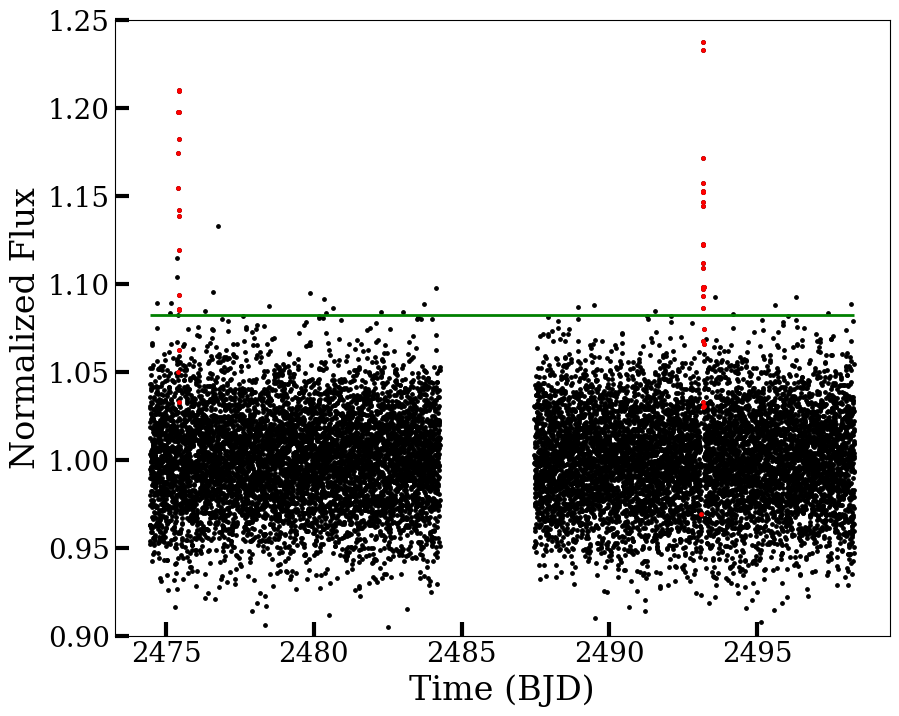

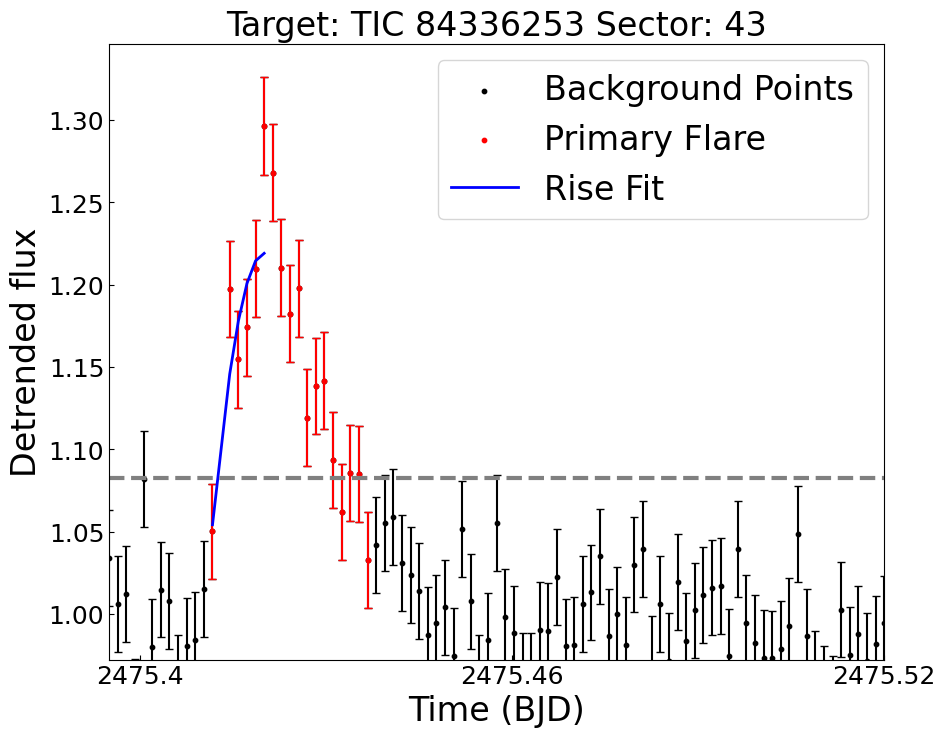

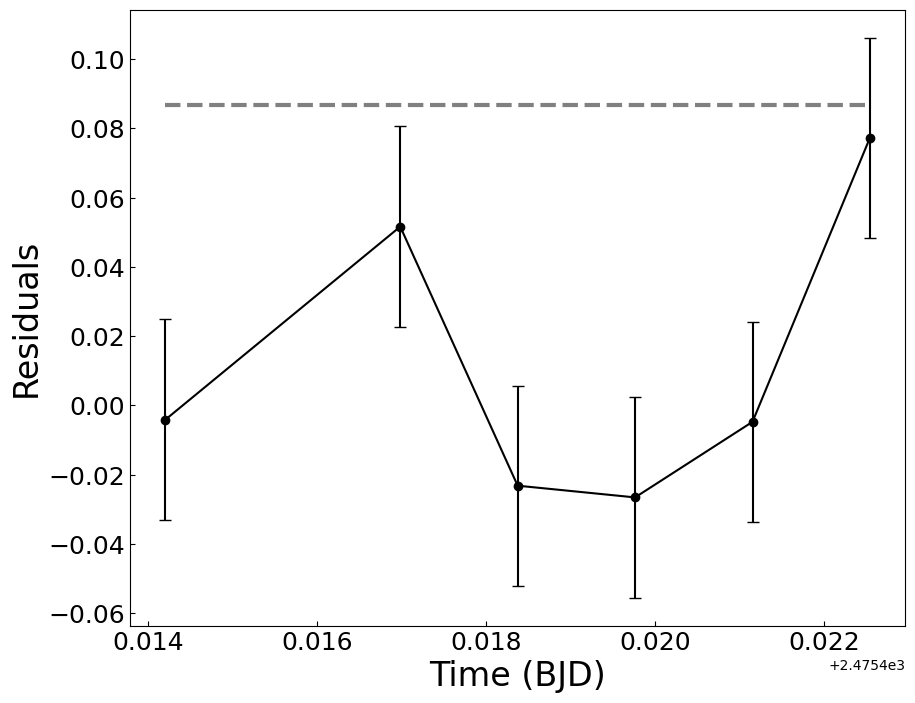

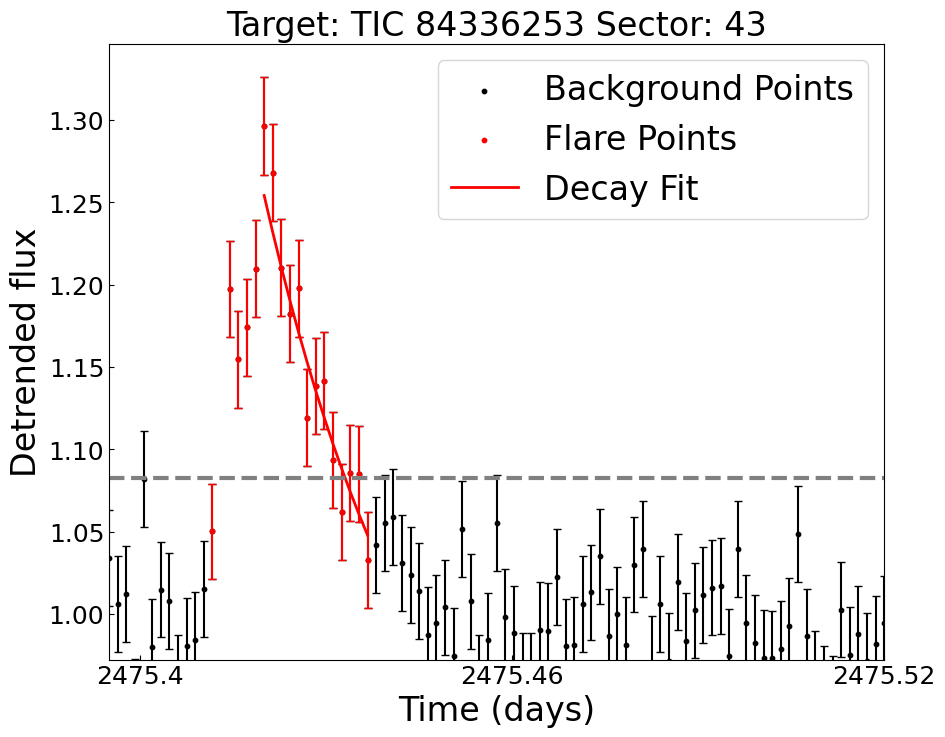

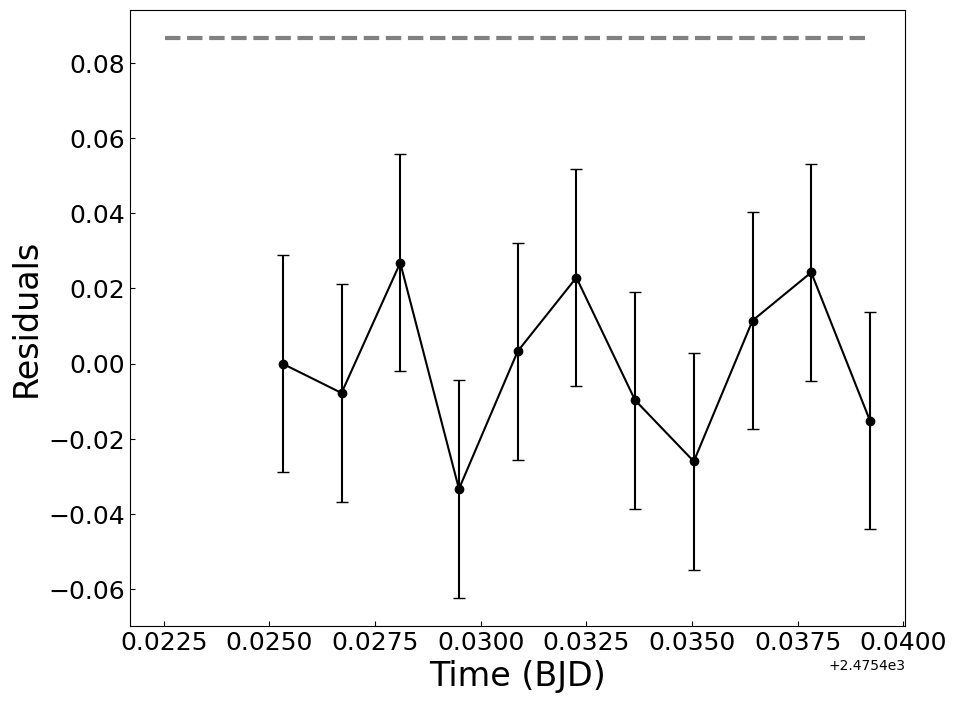

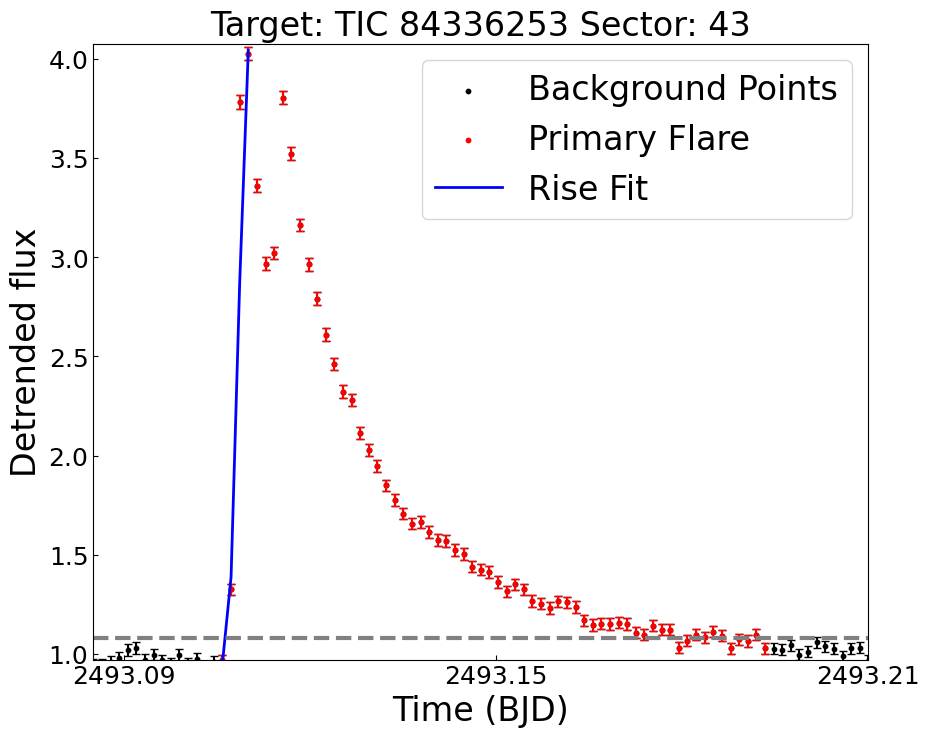

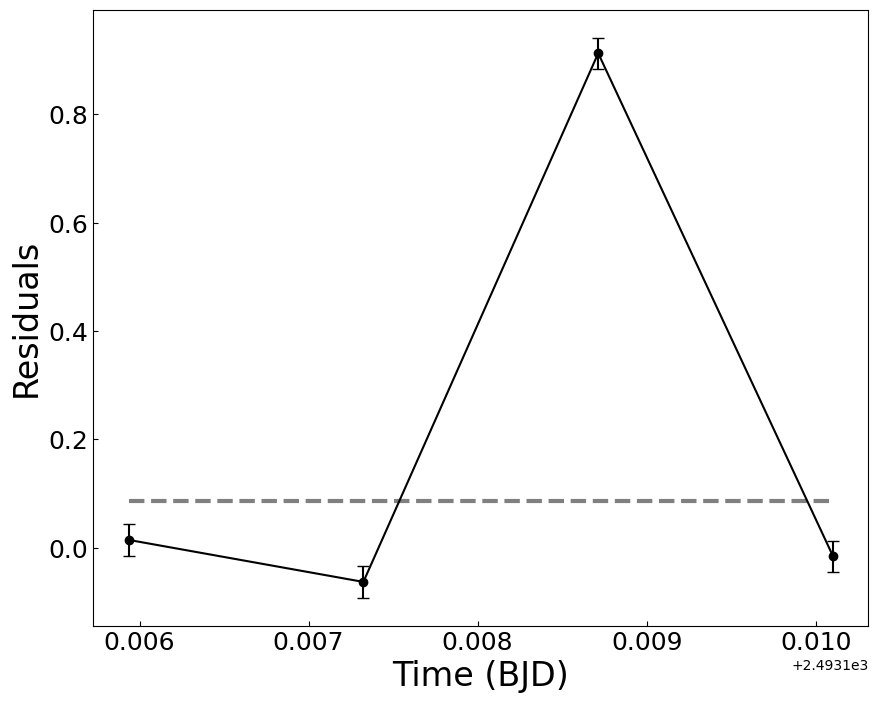

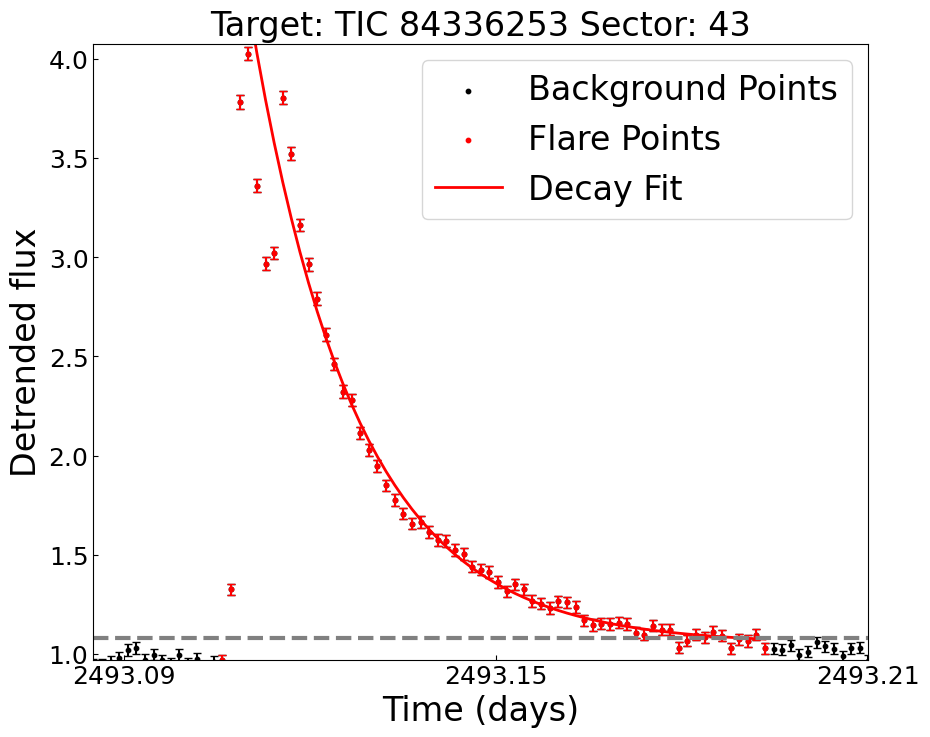

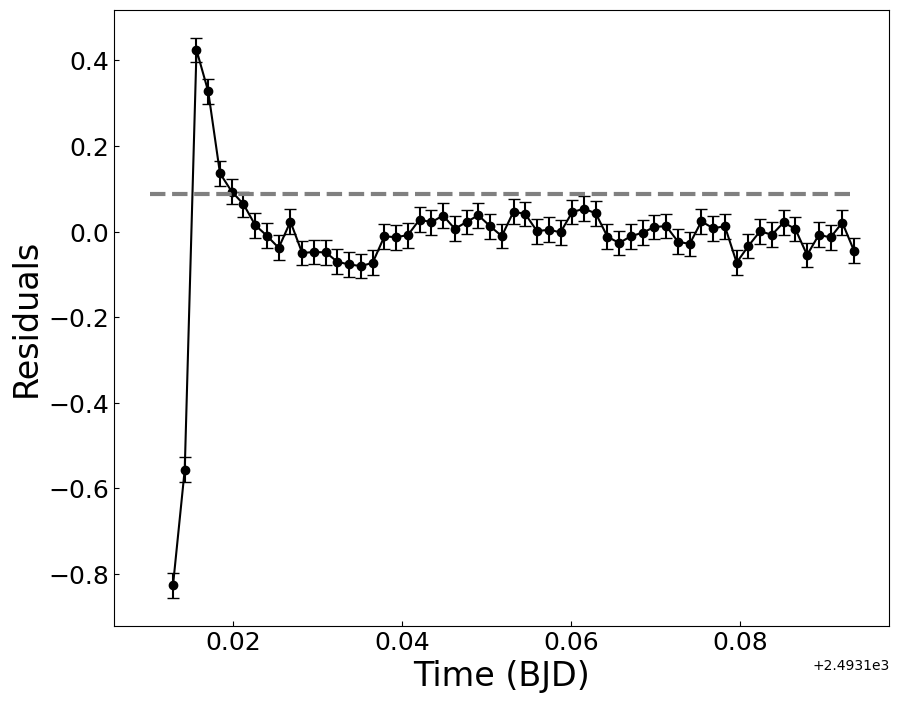

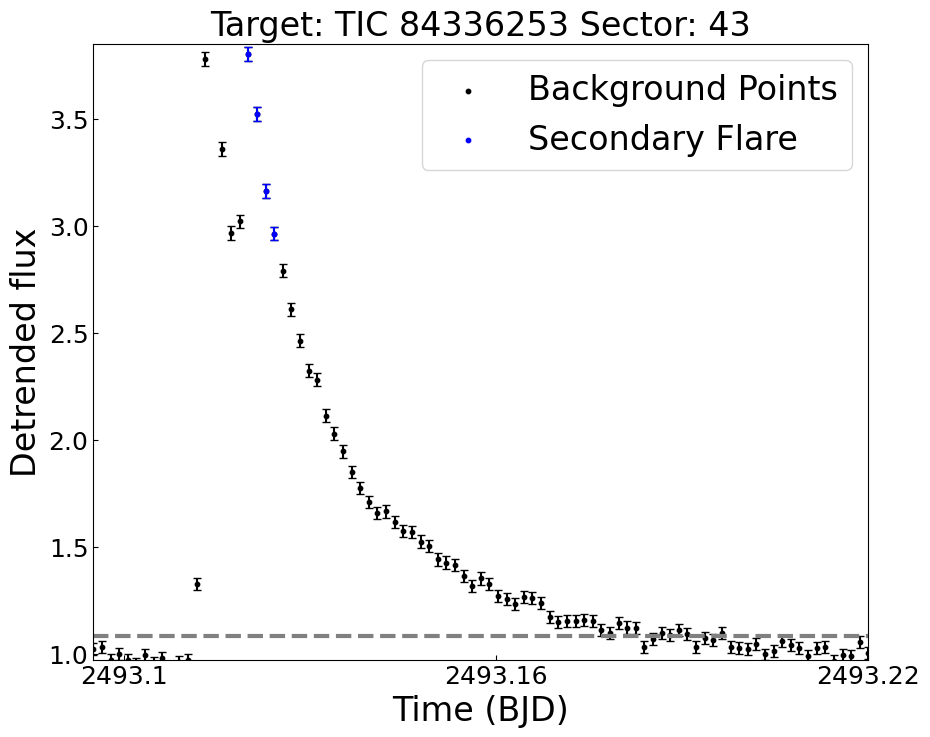

In [8]:
toffee.visualizer(orbit_time, flat_flux, flat_flux_err, orbit_quality,
                  Target = f'TIC {TIC_ID}', Sector = SECTOR)

## That's the whole core workflow

Download a light curve, `flatten()` it, `detect_flares()` on it, read the DataFrame. The next notebooks go deeper on each stage:

- **Notebook 2**: `flatten()`'s arguments and varying return shape, plus break/gap masking
- **Notebook 3**: the flare-decay models underneath `detect_flares()`, using the overlapping pair in this same light curve as a worked example
- **Notebooks 4-5**: the two purity methods (red-noise smoothing, square-index cutting)